In [2]:
from radio_utilities import *
import json
import urllib.request
import pandas as pd
import time
import io
from zoneinfo import ZoneInfo
from astropy.time import Time

In [4]:
# '../data/20260805/20260805_RT1_B.fits'

with fits.open('../data/20261010_taitam/20261010_RT1.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT1 = astro_table.to_pandas()
    
x_RT1 = RT1['JD']
y_RT1 = RT1['RIGHT_POL'].values
#y_RT1 = RT1['LEFT_POL'].values


with fits.open('../data/20261010_taitam/20261010_TAITAM.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT2 = astro_table.to_pandas()
    
x_RT2 = RT2['JD']
y_RT2 = RT2['RIGHT_POL'].values
#y_RT2 = RT2['LEFT_POL'].values

# !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#y_RT2 = RT1['LEFT_POL'].values
#y_RT1 = RT1['LEFT_POL'].values

In [14]:
RT1.columns.values,RT2.columns.values

(<StringArray>
 [        'JD',    'Azimuth',  'Elevation',  'Az_Offset',  'El_Offset',
    'Gal_Long',    'Gal_Lat',   'LEFT_POL',  'RIGHT_POL',  'LEFT_FILT',
  'RIGHT_FILT',     'BBC02u',     'BBC03u',     'BBC04u',     'BBC05u',
      'BBC06u',     'BBC10u',     'BBC11u',     'BBC13u',     'BBC14u',
         'CAL',     'MARKER']
 Length: 22, dtype: str,
 <StringArray>
 [        'JD',    'Azimuth',  'Elevation',  'Az_Offset',  'El_Offset',
    'Gal_Long',    'Gal_Lat',   'LEFT_POL',  'RIGHT_POL',  'LEFT_FILT',
  'RIGHT_FILT',     'BBC02u',     'BBC03u',     'BBC04u',     'BBC05u',
      'BBC06u',     'BBC10u',     'BBC11u',     'BBC12u',     'BBC13u',
      'BBC14u',        'CAL',     'MARKER']
 Length: 23, dtype: str)

In [15]:
#RT1[['BBC02u','BBC03u','BBC04u','BBC05u','BBC06u',
#     'BBC10u','BBC11u','BBC12u','BBC13u','BBC14u']].head()
RT1[['BBC02u','BBC03u','BBC04u','BBC05u','BBC06u',
     'BBC10u','BBC11u','BBC13u','BBC14u']].head()

,BBC02u,BBC03u,BBC04u,BBC05u,BBC06u,BBC10u,BBC11u,BBC13u,BBC14u
0,27,25,23,18,15,58,55,39,31
1,27,25,23,18,15,58,54,39,31
2,27,25,23,18,15,58,55,39,31
3,27,25,23,18,15,58,55,39,31
4,27,25,23,18,15,58,55,39,31


In [51]:
time_peak_rt1 = print_time_peak(x_RT1,y_RT1,timezone="HKT")
time_peak_rt2 = print_time_peak(x_RT2,y_RT2,timezone="HKT")
print("")

Hong Kong Time: 2026-10-11 14:29:16 HKT
Hong Kong Time: 2026-10-10 14:29:32 HKT



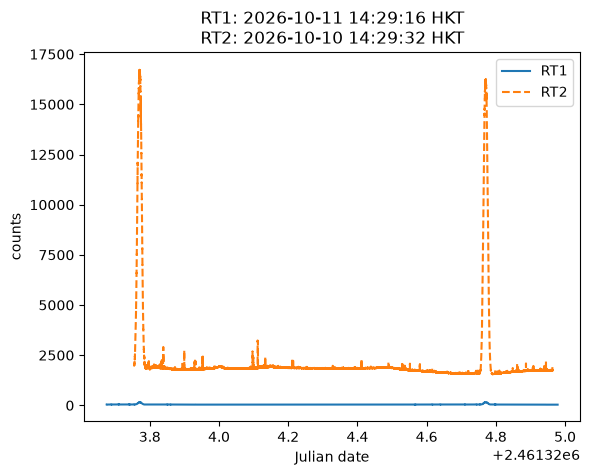

In [52]:
plt.plot(x_RT1,y_RT1,label='RT1')
plt.plot(x_RT2,y_RT2,label='RT2',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('counts')
#plt.title('31/07/2026')
plt.title("RT1: "+time_peak_rt1+"\n"+"RT2: "+time_peak_rt2)
plt.legend()
#plt.savefig('./20260731/uncalibrated.png')
plt.show()

In [53]:
# Cut only one peak RT1
x_RT1_cut = np.array(x_RT1[int(np.argmax(y_RT1)-4000):int(np.argmax(y_RT1)+4000)])
y_RT1_cut = np.array(y_RT1[int(np.argmax(y_RT1)-4000):int(np.argmax(y_RT1)+4000)])
# Cut only one peak RT2
x_RT2_cut = np.array(x_RT2[int(np.argmax(y_RT2)-2100):int(np.argmax(y_RT2)+2100)])
y_RT2_cut = np.array(y_RT2[int(np.argmax(y_RT2)-2100):int(np.argmax(y_RT2)+2100)])


###### TIME INFO #######
UTC Time:       2026-10-11 06:30:01.658
Hong Kong Time: 2026-10-11 14:30:01 HKT
### Gaussian Fit ###
Amplitude 118.31878268188646
Centre [Julian date] 2461324.770852523
Sigma [Days] 0.005331866390656939
Sigma [min] 7.677887602545993
Background floor [adu] 40.99540561959079
FWHM [days] 0.012555585614046775
FWHM [min] 18.080043284227358
Estimated antenna beam with 0.25 deg/min 4.5200108210568395


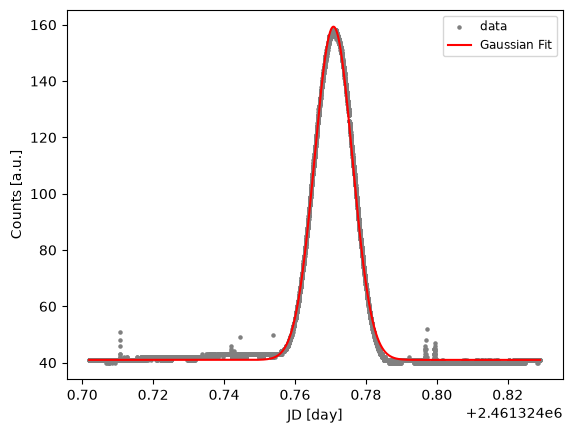

In [54]:
Amp_adu_rt1, centre_jd_rt1, sigma_jd_rt1, floor_adu_rt1, fwhm_day_rt1 =  gauss_fit(x_RT1_cut,y_RT1_cut,verbose=True,plot=True)

###### TIME INFO #######
UTC Time:       2026-10-10 06:29:32.272
Hong Kong Time: 2026-10-10 14:29:32 HKT
### Gaussian Fit ###
Amplitude 16183.21837898435
Centre [Julian date] 2461323.770512408
Sigma [Days] 0.006138491369690194
Sigma [min] 8.839427572353879
Background floor [adu] 805.9026968412807
FWHM [days] 0.014455042247173863
FWHM [min] 20.81526083593036
Estimated antenna beam with 0.25 deg/min 5.20381520898259


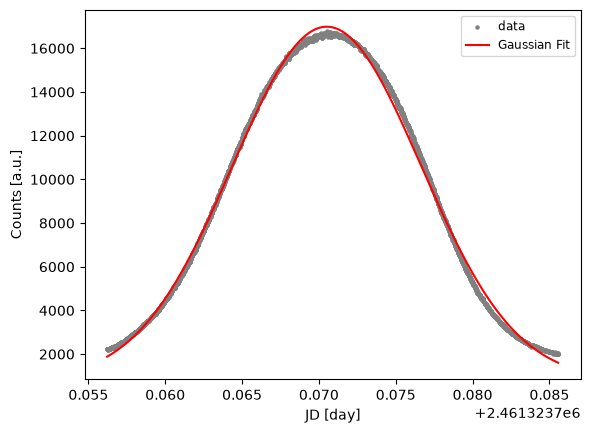

In [55]:
Amp_adu_rt2, centre_jd_rt2, sigma_jd_rt2, floor_adu_rt2, fwhm_day_rt2 =  gauss_fit(x_RT2_cut,y_RT2_cut,verbose=True,plot=True)

In [56]:
time_peak_rt1,time_peak_rt2

('2026-10-11 14:29:16 HKT', '2026-10-10 14:29:32 HKT')

In [57]:
time_peak_rt1_str =time_peak_rt1[2:4]+time_peak_rt1[5:7]+time_peak_rt1[8:10]
time_peak_rt2_str =time_peak_rt2[2:4]+time_peak_rt2[5:7]+time_peak_rt2[8:10]

In [58]:
# it only gets the day so RT1 and Rt2 are the same
f14 = get_solar_flux_on_date(time_peak_rt1_str,verbose=True)

In [59]:
print(f14)

None


In [60]:
f14 = 124.4

In [61]:
K_RT1 = get_conversion_K(x_RT1,y_RT1,amp_adu=Amp_adu_rt1,solar_flux_sfu=f14)
print('Conversion factor between ADU to Antenna temperature (RT1): ',K_RT1)

K_RT2 = get_conversion_K(x_RT2,y_RT2,amp_adu=Amp_adu_rt2,solar_flux_sfu=f14)
print('Conversion factor between ADU to Antenna temperature (RT1): ',K_RT2)

Conversion factor between ADU to Antenna temperature (RT1):  16.156275368015322
Conversion factor between ADU to Antenna temperature (RT1):  0.11812179687937267


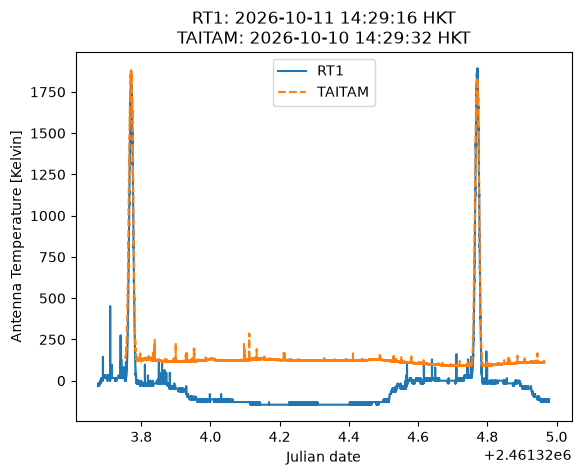

In [62]:
plt.plot(x_RT1,K_RT1*(y_RT1-floor_adu_rt1),label='RT1')
plt.plot(x_RT2,K_RT2*(y_RT2-floor_adu_rt2),label='TAITAM',ls='--')
#plt.xlim(0,200)
#plt.ylim(200,400)
plt.xlabel('Julian date')
plt.ylabel('Antenna Temperature [Kelvin]')
plt.title("RT1: "+time_peak_rt1+"\n"+"TAITAM: "+time_peak_rt2)
#plt.savefig('./20260731/calibrated_fitsun2807.png')
plt.legend()
plt.show()

